# Module 12 — Exercises — Solutions

These exercises follow the order of the concept guide: the logic of a test and p-values, power and sample
size, t-tests (Welch and paired), proportions and chi-square, permutation tests, multiple comparisons,
experimental design, peeking, and finally comparing machine-learning models. Several checks compare your
answer against a *hidden* value, so compute carefully rather than guessing. `statsmodels` is not available
(and not needed): everything is NumPy plus `scipy.stats`.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb
from itertools import combinations
from scipy import stats
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Exact binomial p-value versus the normal approximation  `★☆☆`

Implement two functions for testing $H_0: \theta = \theta_0$ with $k$ successes in $n$ trials:

* `binom_two_sided_p(k, n, theta0=0.5)` — the exact two-sided p-value as the **doubled smaller tail**,
  $\min\big(1,\ 2\min(P(X \le k),\ P(X \ge k))\big)$ with $X \sim \text{Binomial}(n, \theta_0)$. Use
  `stats.binom.cdf` / `stats.binom.sf` (careful: `sf(k)` is $P(X > k)$, not $P(X \ge k)$). Return a float.
* `normal_approx_p(k, n, theta0=0.5, continuity=True)` — the two-sided normal-approximation p-value,
  $2\big(1 - \Phi(z)\big)$ with $z = \big(|k - n\theta_0| - \tfrac12\big)/\sqrt{n\theta_0(1-\theta_0)}$ when
  `continuity=True` (clip the numerator at 0) and without the $\tfrac12$ otherwise.

In [3]:
def binom_two_sided_p(k, n, theta0=0.5):
    lower = stats.binom.cdf(k, n, theta0)          # P(X <= k)
    upper = stats.binom.sf(k - 1, n, theta0)       # P(X >= k)
    return float(min(1.0, 2 * min(lower, upper)))

def normal_approx_p(k, n, theta0=0.5, continuity=True):
    mu = n * theta0
    sd = np.sqrt(n * theta0 * (1 - theta0))
    dev = abs(k - mu) - (0.5 if continuity else 0.0)
    dev = max(dev, 0.0)
    return float(2 * stats.norm.sf(dev / sd))

**Check your answer:**

In [4]:
try:
    got = binom_two_sided_p(50, 100)
except Exception:
    got = None
check_close('50 heads in 100 flips: p = 1', got, 1.0)
try:
    got = binom_two_sided_p(60, 100)
except Exception:
    got = None
check_hash('exact two-sided p for 60/100', got, '32cbcfcaa14e5d48', decimals=4)
try:
    got = binom_two_sided_p(40, 100)
except Exception:
    got = None
check_hash('symmetry: 40/100 gives the same p', got, '32cbcfcaa14e5d48', decimals=4)
try:
    got = normal_approx_p(60, 100, continuity=True)
except Exception:
    got = None
check_hash('normal approximation with continuity correction, 60/100', got, '81c19613769a0491', decimals=4)
try:
    got = normal_approx_p(60, 100, continuity=False)
except Exception:
    got = None
check_close('normal approximation without correction, 60/100', got, 2 * stats.norm.sf(2.0), tol=1e-6)
try:
    got = binom_two_sided_p(14, 30, 0.3)
except Exception:
    got = None
check_hash('asymmetric case: 14/30 under theta0 = 0.3', got, 'c535ca2d6acde81a', decimals=4)

✅ 50 heads in 100 flips: p = 1
✅ exact two-sided p for 60/100
✅ symmetry: 40/100 gives the same p
✅ normal approximation with continuity correction, 60/100
✅ normal approximation without correction, 60/100
✅ asymmetric case: 14/30 under theta0 = 0.3


True

**Why this works**

The p-value is the null probability of a result at least as extreme as the observed one; for a two-sided
alternative on a symmetric binomial, doubling the smaller tail is the natural definition and coincides
with scipy's `binomtest` when $\theta_0 = 0.5$ (for asymmetric $\theta_0$ the two conventions can differ
slightly — that is not a bug, two-sided p-values for discrete tests are genuinely a matter of definition).
The most common wrong turn is `stats.binom.sf(k, n, theta0)`, which is $P(X > k)$ and silently drops the
observed outcome itself; use `sf(k - 1)` or `1 - cdf(k - 1)`. The continuity correction moves the normal
approximation from $0.046$ to $0.057$, within $0.001$ of the exact $0.057$.

## Exercise 2 — Power, required sample size and minimum detectable effect  `★☆☆`

For the two-sample z-test (known $\sigma$, $n$ per arm, two-sided level $\alpha$) implement

* `power_two_sample_z(delta, sigma, n, alpha=0.05)` — the power
  $\Phi\big(\tfrac{\delta}{\sigma\sqrt{2/n}} - z_{1-\alpha/2}\big) + \Phi\big(-\tfrac{\delta}{\sigma\sqrt{2/n}} - z_{1-\alpha/2}\big)$ as a float;
* `n_per_arm(delta, sigma, power=0.8, alpha=0.05)` — the required sample size per arm,
  $\big\lceil 2(z_{1-\alpha/2} + z_{1-\beta})^2\sigma^2/\delta^2 \big\rceil$, as an **int**;
* `mde(sigma, n, power=0.8, alpha=0.05)` — the minimum detectable effect $(z_{1-\alpha/2} + z_{1-\beta})\,\sigma\sqrt{2/n}$ as a float.

Use `stats.norm.ppf` for the quantiles and `stats.norm.cdf` / `stats.norm.sf` for $\Phi$.

In [5]:
def power_two_sample_z(delta, sigma, n, alpha=0.05):
    se = sigma * np.sqrt(2.0 / n)
    zc = stats.norm.ppf(1 - alpha / 2)
    return float(stats.norm.cdf(-zc - delta / se) + stats.norm.sf(zc - delta / se))

def n_per_arm(delta, sigma, power=0.8, alpha=0.05):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil(2 * (za + zb)**2 * sigma**2 / delta**2))

def mde(sigma, n, power=0.8, alpha=0.05):
    return float((stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)) * sigma * np.sqrt(2.0 / n))

**Check your answer:**

In [6]:
try:
    got = power_two_sample_z(0.0, 10.0, 50)
except Exception:
    got = None
check_close('no effect: power equals alpha = 0.05', got, 0.05, tol=1e-6)
try:
    got = power_two_sample_z(4.0, 10.0, 100)
except Exception:
    got = None
check_close('delta 4, sigma 10, n 100: power ~ 0.807', got, 0.8074, tol=1e-3)
try:
    got = power_two_sample_z(4.0, 10.0, 50)
except Exception:
    got = None
check_hash('power at n = 50', got, 'fda94e1202ba6f6b', decimals=3)
try:
    got = n_per_arm(4.0, 10.0)
    ok_int = isinstance(got, (int, np.integer))
except Exception:
    got, ok_int = None, False
check('n_per_arm returns an integer', ok_int)
check_hash('n per arm for delta 4, sigma 10, 80% power', got, '8c1f1046219ddd21')
try:
    got = n_per_arm(0.5, 2.0, power=0.9)
except Exception:
    got = None
check_hash('n per arm for delta 0.5, sigma 2, 90% power', got, '8ede6b26343305e0')
try:
    got = mde(10.0, 50)
except Exception:
    got = None
check_hash('MDE for sigma 10, n 50', got, '223623a06ccfbf48', decimals=3)
try:
    got = power_two_sample_z(mde(10.0, 50), 10.0, 50)
except Exception:
    got = None
check_close('consistency: power at the MDE is 0.8', got, 0.8, tol=1e-3)

✅ no effect: power equals alpha = 0.05
✅ delta 4, sigma 10, n 100: power ~ 0.807
✅ power at n = 50
✅ n_per_arm returns an integer
✅ n per arm for delta 4, sigma 10, 80% power
✅ n per arm for delta 0.5, sigma 2, 90% power
✅ MDE for sigma 10, n 50
✅ consistency: power at the MDE is 0.8


True

**Why this works**

Under $H_1$ the standardised difference is $\mathcal N(\delta/\text{SE}, 1)$ with $\text{SE} = \sigma\sqrt{2/n}$,
and the test rejects when it falls outside $\pm z_{1-\alpha/2}$; the two $\Phi$ terms are the two tails of that
shifted normal. Setting the main term to $1 - \beta$ gives $\delta/\text{SE} = z_{1-\alpha/2} + z_{1-\beta}$, which
solves to the sample-size and MDE formulas (the tiny wrong-direction term is dropped, so the power at the MDE
is $0.8$ to three decimals rather than exactly). Common slips: forgetting the factor 2 (two arms contribute
variance), using $z_{1-\alpha}$ instead of $z_{1-\alpha/2}$ for a two-sided test, and returning a float where a
sample size must be rounded *up* to an integer.

## Exercise 3 — Welch's t-test from scratch  `★☆☆`

Implement `welch_t(x, y)` returning the tuple `(t, df, p)` for two independent samples:

$$t = \frac{\bar x - \bar y}{\sqrt{s_x^2/n_x + s_y^2/n_y}}, \qquad
\nu = \frac{(s_x^2/n_x + s_y^2/n_y)^2}{\dfrac{(s_x^2/n_x)^2}{n_x - 1} + \dfrac{(s_y^2/n_y)^2}{n_y - 1}}, \qquad
p = 2\,P(t_\nu \ge |t|).$$

Use sample variances with `ddof=1` and `stats.t.sf` for the tail probability. Do **not** call
`stats.ttest_ind` inside the function (the checks compare against it).

In [7]:
def welch_t(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    n1, n2 = len(x), len(y)
    v1, v2 = x.var(ddof=1) / n1, y.var(ddof=1) / n2
    t = (x.mean() - y.mean()) / np.sqrt(v1 + v2)
    df = (v1 + v2)**2 / (v1**2 / (n1 - 1) + v2**2 / (n2 - 1))
    p = 2 * stats.t.sf(abs(t), df)
    return float(t), float(df), float(p)

**Check your answer:**

In [8]:
old = np.array([52., 48, 55, 50, 53, 49, 51, 54]); new = np.array([47., 50, 44, 49, 46, 48])
ref = stats.ttest_ind(old, new, equal_var=False)
try:
    t, df, p = welch_t(old, new)
except Exception:
    t, df, p = None, None, None
check_close('cycle times: t statistic matches scipy', t, ref.statistic)
check_close('cycle times: Welch-Satterthwaite df matches scipy', df, ref.df)
check_close('cycle times: p-value matches scipy', p, ref.pvalue)
_r = np.random.default_rng(3)
x2 = _r.normal(0, 1, 12); y2 = _r.normal(0.5, 4, 40)          # very unequal variances and sizes
ref2 = stats.ttest_ind(x2, y2, equal_var=False)
try:
    t2, df2, p2 = welch_t(x2, y2)
except Exception:
    t2, df2, p2 = None, None, None
check_close('unequal variances: p-value matches scipy', p2, ref2.pvalue)
check('df lies between min(n) - 1 and n1 + n2 - 2', (df2 is not None) and (11 <= df2 <= 50))

✅ cycle times: t statistic matches scipy
✅ cycle times: Welch-Satterthwaite df matches scipy
✅ cycle times: p-value matches scipy
✅ unequal variances: p-value matches scipy
✅ df lies between min(n) - 1 and n1 + n2 - 2


True

**Why this works**

Welch's statistic standardises the difference of means by the *unpooled* standard error, and the
Welch–Satterthwaite formula picks the degrees of freedom for which a scaled chi-square best matches the
distribution of that estimated variance; the result is fractional and lies between $\min(n_x, n_y) - 1$ and
$n_x + n_y - 2$. Typical mistakes: `ddof=0` (population variance), pooling the variances (that is Student's
test), or using `stats.t.cdf` without the factor 2 for a two-sided p-value.

## Exercise 4 — What a p-value is not  `★☆☆`

An A/B test on a new checkout page reports a lift of 0.6 percentage points with $p = 0.03$. For each of the
following statements say whether it is correct, and if not, what the correct statement is:

1. "There is a 3% probability that the new page is no better than the old one."
2. "There is a 97% probability that the new page is better."
3. "If the new page were truly no better, a lift at least this large (in either direction) would occur in about 3% of such experiments."
4. "If we repeated the experiment, it would come out significant 97% of the time."
5. "The result is more trustworthy than a competitor's $p = 0.04$ result from an experiment ten times larger."

**Answer**

Only statement 3 is correct — it is the definition of a two-sided p-value: a probability about *data*
computed under $H_0$. Statement 1 reverses the conditioning: $P(\text{data} \mid H_0) \ne P(H_0 \mid \text{data})$;
the latter needs a prior over hypotheses and Bayes' theorem (with 10% of ideas being real improvements and
power 0.8, a significant result is a false positive about a third of the time). Statement 2 is the same error
for $H_1$. Statement 4 confuses the p-value with power: the replication probability depends on the true
effect and the sample size and, for an effect just large enough to give $p = 0.03$, is only around 50%.
Statement 5 is wrong twice: p-values from different sample sizes are not comparable as "trustworthiness",
and the larger experiment's $p = 0.04$ corresponds to a much *smaller* estimated effect with a much
*narrower* interval — compare effect sizes and confidence intervals, not p-values.

## Exercise 5 — Paired t-test and the cost of ignoring the pairing  `★★☆`

Six machines were timed before and after a maintenance change (minutes per cycle):

```
before = [31.0, 28.5, 35.2, 30.1, 27.8, 33.4]
after  = [29.1, 27.9, 33.0, 29.6, 27.0, 31.5]
```

1. Implement `paired_t(before, after)` returning `(t, df, p)` for the paired t-test on the differences
   $d_i = \text{before}_i - \text{after}_i$: $t = \bar d/(s_d/\sqrt n)$, $\nu = n - 1$ (an int), two-sided $p$.
   Do not call `stats.ttest_rel` inside the function.
2. Assign `t_paired, df_paired, p_paired = paired_t(before, after)`.
3. Assign `p_unpaired` = the two-sided p-value of **Welch's** test on the same two arrays (you may use
   `stats.ttest_ind(..., equal_var=False)` here), to see what ignoring the pairing costs.

In [9]:
def paired_t(before, after):
    d = np.asarray(before, float) - np.asarray(after, float)
    n = len(d)
    se = d.std(ddof=1) / np.sqrt(n)
    t = d.mean() / se if se > 0 else np.sign(d.mean()) * np.inf     # all differences equal -> infinite t
    df = n - 1
    p = 2 * stats.t.sf(abs(t), df)
    return float(t), int(df), float(p)

before = np.array([31.0, 28.5, 35.2, 30.1, 27.8, 33.4])
after = np.array([29.1, 27.9, 33.0, 29.6, 27.0, 31.5])
t_paired, df_paired, p_paired = paired_t(before, after)
p_unpaired = float(stats.ttest_ind(before, after, equal_var=False).pvalue)

**Check your answer:**

In [10]:
check_hash('paired t statistic', t_paired, '2dc1d1db43a8acf2', decimals=3)
check_hash('degrees of freedom', df_paired, 'ef2d127de37b942b')
check_hash('paired p-value', p_paired, '6e8117e55f1abda1', decimals=3)
try:
    got = paired_t(before, after)[2]
except Exception:
    got = None
check_close('matches stats.ttest_rel', got, stats.ttest_rel(before, after).pvalue)
check('unpaired Welch p-value is above 0.3 on the same numbers', (p_unpaired is not None) and p_unpaired > 0.3)
check('pairing makes the p-value more than 20 times smaller', (p_paired is not None and p_unpaired is not None) and p_unpaired / p_paired > 20)
try:
    got = paired_t(np.array([1., 2., 3., 4.]), np.array([0., 1., 2., 3.]) )
    ok = got is not None and np.isinf(got[0]) or (got is not None and abs(got[0]) > 1e6)
except Exception:
    ok = False
check('constant differences give an infinite (or huge) t', ok)

✅ paired t statistic
✅ degrees of freedom
✅ paired p-value
✅ matches stats.ttest_rel
✅ unpaired Welch p-value is above 0.3 on the same numbers
✅ pairing makes the p-value more than 20 times smaller
✅ constant differences give an infinite (or huge) t


True

**Why this works**

The paired test is a one-sample test on the differences: $\bar d = 1.317$, $s_d = 0.763$,
$t = 1.317/(0.763/\sqrt 6) = 4.23$ on 5 degrees of freedom, $p = 0.008$. The unpaired Welch test on the same
twelve numbers gives $p \approx 0.40$ because the between-machine spread (about 2.9 minutes) enters the
standard error, whereas the differences remove it; the before/after correlation is $0.98$. When every
difference is identical, $s_d = 0$ and $t = \pm\infty$ — a degenerate but correct answer (guard the division
so NumPy does not warn). The classic bug is to compute `before.std() - after.std()` or to pool variances
as if the samples were independent.

## Exercise 6 — Chi-square test of a 2 x 2 table and its identity with the z-test  `★★☆`

Implement

* `chi2_2x2(table)` — for a $2 \times 2$ array of counts, return `(chi2, p, expected)` where
  `expected[i, j] = R_i C_j / N` (row total times column total over the grand total),
  $\chi^2 = \sum_{ij}(O_{ij} - E_{ij})^2/E_{ij}$ **without** continuity correction, and $p = P(\chi^2_1 \ge \chi^2)$;
* `two_prop_z(x1, n1, x2, n2)` — the two-proportion z-statistic $(\hat\theta_2 - \hat\theta_1)/\sqrt{\bar\theta(1-\bar\theta)(1/n_1 + 1/n_2)}$ with the pooled rate $\bar\theta$.

Then convince yourself numerically that $\chi^2 = z^2$ for the conversion table `[[200, 3800], [240, 3760]]`
(rows = variants A and B, columns = converted / not converted).

In [11]:
def chi2_2x2(table):
    table = np.asarray(table, float)
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / table.sum()
    chi2 = ((table - expected)**2 / expected).sum()
    p = stats.chi2.sf(chi2, 1)
    return float(chi2), float(p), expected

def two_prop_z(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    pbar = (x1 + x2) / (n1 + n2)
    return float((p2 - p1) / np.sqrt(pbar * (1 - pbar) * (1 / n1 + 1 / n2)))

**Check your answer:**

In [12]:
conv = np.array([[200, 3800], [240, 3760]])
ref = stats.chi2_contingency(conv, correction=False)
try:
    chi2, p, E = chi2_2x2(conv)
except Exception:
    chi2, p, E = None, None, None
check_close('conversion table: chi2 matches scipy (no correction)', chi2, ref.statistic)
check_close('conversion table: p matches scipy', p, ref.pvalue)
check_close('expected counts', E, ref.expected_freq)
try:
    z = two_prop_z(200, 4000, 240, 4000)
except Exception:
    z = None
check_hash('two-proportion z for the conversion table', z, '32b357899515e9d2', decimals=3)
check_close('chi2 equals z squared', (z**2 if z is not None else None), chi2 if chi2 is not None else -1.0, tol=1e-9)
try:
    chi2s, ps, Es = chi2_2x2([[30, 170], [18, 182]])
except Exception:
    chi2s, ps = None, None
check_hash('side-effect table: chi2 statistic', chi2s, '8eae139162c567a7', decimals=3)
check_hash('side-effect table: p-value', ps, 'a79ac230af93369e', decimals=3)

✅ conversion table: chi2 matches scipy (no correction)
✅ conversion table: p matches scipy
✅ expected counts
✅ two-proportion z for the conversion table
✅ chi2 equals z squared
✅ side-effect table: chi2 statistic
✅ side-effect table: p-value


True

**Why this works**

Under independence the expected count in a cell is (row share) $\times$ (column share) $\times N$, i.e.
$R_i C_j/N$. For a $2 \times 2$ table all four $|O - E|$ are equal, and a few lines of algebra turn
$\sum (O - E)^2/E$ into $(\hat\theta_2 - \hat\theta_1)^2/[\bar\theta(1-\bar\theta)(1/n_1 + 1/n_2)] = z^2$ — the two
tests are one test, which is why their p-values agree exactly ($0.0498$ here). The degrees of freedom are
$(2-1)(2-1) = 1$. Watch out for `np.outer(table.sum(0), table.sum(1))`, which transposes the expected
counts (harmless for symmetric margins, wrong in general), and for applying Yates's correction when the
exercise asks for the plain statistic.

## Exercise 7 — Permutation tests: exact and Monte Carlo  `★★☆`

Implement two permutation tests for the two-sided null "the two samples come from the same distribution",
using the absolute difference of means as the statistic:

* `exact_perm_p(a, b)` — enumerate **all** $\binom{n_a + n_b}{n_a}$ ways to choose which pooled observations
  form group $a$ (`itertools.combinations`), and return the fraction of splits whose
  $|\bar a^* - \bar b^*|$ is $\ge$ the observed value (use a tolerance such as `>= obs - 1e-12` to be safe with
  floating point). Only for tiny samples.
* `perm_test_mc(a, b, n_perm, rng)` — shuffle the pooled data `n_perm` times with `rng.permutation`, take the
  first $n_a$ values as the new group $a$, and return $\dfrac{1 + \#\{|T^*| \ge |t_{\text{obs}}|\}}{n_{\text{perm}} + 1}$.

Data for the Monte Carlo test (skewed spend per customer, 40 per arm) are generated below with a fixed seed.

```python
_r = np.random.default_rng(7)
spend_a = np.round(_r.exponential(20.0, 40), 2)          # control: skewed spend, mean 20
spend_b = np.round(_r.exponential(28.0, 40), 2)          # treatment: mean 28
```

In [13]:
_r = np.random.default_rng(7)
spend_a = np.round(_r.exponential(20.0, 40), 2)          # control: skewed spend, mean 20
spend_b = np.round(_r.exponential(28.0, 40), 2)          # treatment: mean 28


def exact_perm_p(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    pooled = np.concatenate([a, b]); n1 = len(a)
    obs = abs(a.mean() - b.mean())
    count, total = 0, 0
    for idx in combinations(range(len(pooled)), n1):
        idx = list(idx)
        rest = np.delete(pooled, idx)
        diff = abs(pooled[idx].mean() - rest.mean())
        count += diff >= obs - 1e-12
        total += 1
    return count / total

def perm_test_mc(a, b, n_perm, rng):
    a, b = np.asarray(a, float), np.asarray(b, float)
    pooled = np.concatenate([a, b]); n1 = len(a)
    obs = abs(a.mean() - b.mean())
    count = 0
    for _ in range(n_perm):
        perm = rng.permutation(pooled)
        count += abs(perm[:n1].mean() - perm[n1:].mean()) >= obs - 1e-12
    return (1 + count) / (n_perm + 1)

**Check your answer:**

In [14]:
try:
    got = exact_perm_p([12., 15, 11], [9., 8, 10])
except Exception:
    got = None
check_hash('exact two-sided p for the 3-vs-3 example', got, 'cc1a4126ba1a738f', decimals=3)
try:
    got = exact_perm_p([1., 2., 3.], [1., 2., 3.])
except Exception:
    got = None
check_close('identical groups: every split is at least as extreme, p = 1', got, 1.0)
try:
    got = exact_perm_p([5., 6., 7., 8.], [1., 2., 3., 4.])
except Exception:
    got = None
check_close('completely separated 4-vs-4 groups: p = 2/70', got, 2 / 70)
try:
    p_mc = perm_test_mc(spend_a, spend_b, 5_000, np.random.default_rng(1))
except Exception:
    p_mc = None
check('Monte Carlo p is a probability in (0, 1]', (p_mc is not None) and 0 < p_mc <= 1)
check('Monte Carlo p within 0.015 of the reference value', (p_mc is not None) and abs(p_mc - 0.0397) < 0.015,
      hint='did you compare |T*| with |t_obs| and add 1 to numerator and denominator?')
try:
    p_same = perm_test_mc(spend_a, spend_a, 2_000, np.random.default_rng(2))
except Exception:
    p_same = None
check('a sample against itself: p = 1', (p_same is not None) and abs(p_same - 1.0) < 1e-12)

✅ exact two-sided p for the 3-vs-3 example
✅ identical groups: every split is at least as extreme, p = 1
✅ completely separated 4-vs-4 groups: p = 2/70
✅ Monte Carlo p is a probability in (0, 1]
✅ Monte Carlo p within 0.015 of the reference value
✅ a sample against itself: p = 1


True

**Why this works**

Under the null the group labels are exchangeable, so every assignment of the pooled values to the two
groups is equally likely and the fraction of assignments with a statistic at least as extreme as the one
observed *is* the p-value — no distributional assumption anywhere. For 3 vs 3 there are 20 splits, and
only the observed one and its mirror image reach $|{\bar a} - {\bar b}| = 3.67$, so $p = 0.10$; for the
separated 4-vs-4 case the two extreme splits out of $\binom 84 = 70$ give $2/70$. The Monte Carlo version
estimates the same fraction with random permutations; adding 1 to numerator and denominator counts the
observed arrangement itself and guarantees the estimated p-value is never 0 and remains valid. Comparing a
sample against itself gives $p = 1$ because every permutation ties the observed statistic of exactly 0.
The reference value for the skewed spend data is close to Welch's p-value here (40 per arm is enough for
the CLT), but the permutation test would stay exact at 8 per arm, where the t-test would not.

## Exercise 8 — Bonferroni, Holm and Benjamini–Hochberg  `★★☆`

Implement three functions that take an array of (unsorted) p-values and return a **boolean array** of the
same length, `True` where the hypothesis is rejected:

* `bonferroni_reject(p, alpha=0.05)` — reject if $p_i \le \alpha/m$;
* `holm_reject(p, alpha=0.05)` — sort the p-values; compare $p_{(i)}$ with $\alpha/(m - i + 1)$ for
  $i = 1, 2, \dots$; reject all hypotheses **before the first failure** and nothing after it (step-down);
* `bh_reject(p, q=0.05)` — sort; find the **largest** $k$ with $p_{(k)} \le kq/m$; reject the $k$ hypotheses with
  the smallest p-values (step-up), or none if no such $k$ exists.

Remember to map the decisions back to the original order (use `np.argsort`). Apply them to the twelve
p-values below; the checks hash the sorted *indices* of the rejected hypotheses.

```python
pvals = np.array([0.040, 0.350, 0.001, 0.019, 0.600, 0.012, 0.200, 0.045, 0.011, 0.900, 0.004, 0.030])
```

In [15]:
pvals = np.array([0.040, 0.350, 0.001, 0.019, 0.600, 0.012, 0.200, 0.045, 0.011, 0.900, 0.004, 0.030])


def bonferroni_reject(p, alpha=0.05):
    p = np.asarray(p, float)
    return p <= alpha / len(p)

def holm_reject(p, alpha=0.05):
    p = np.asarray(p, float); m = len(p)
    order = np.argsort(p)
    thresholds = alpha / (m - np.arange(m))                 # alpha/m, alpha/(m-1), ..., alpha
    passed = p[order] <= thresholds
    k = np.argmin(passed) if not passed.all() else m       # index of the first failure
    reject = np.zeros(m, bool)
    reject[order[:k]] = True
    return reject

def bh_reject(p, q=0.05):
    p = np.asarray(p, float); m = len(p)
    order = np.argsort(p)
    thresholds = q * np.arange(1, m + 1) / m               # q i / m
    passed = np.flatnonzero(p[order] <= thresholds)
    reject = np.zeros(m, bool)
    if len(passed):
        k = passed.max() + 1                               # largest i with p_(i) <= q i / m
        reject[order[:k]] = True
    return reject

**Check your answer:**

In [16]:
def _idx(fn, p, *args):
    try:
        r = np.asarray(fn(p, *args))
        return np.flatnonzero(r).tolist() if r.dtype == bool and r.shape == (len(p),) else None
    except Exception:
        return None
rb, rh, rq = _idx(bonferroni_reject, pvals), _idx(holm_reject, pvals), _idx(bh_reject, pvals)
check('functions return boolean arrays of the right length', rb is not None and rh is not None and rq is not None)
check_hash('Bonferroni rejections (indices)', rb, '1caa7b7fab4b45ed')
check_hash('Holm rejections (indices)', rh, '1caa7b7fab4b45ed')
check_hash('Benjamini-Hochberg rejections at q = 0.05 (indices)', rq, '71e0450c35e7d1fc')
check_hash('Benjamini-Hochberg rejections at q = 0.10 (indices)', _idx(bh_reject, pvals, 0.10), '2c0ad2173807f619')
check('Bonferroni is a subset of Holm, Holm a subset of BH', (rb is not None and rh is not None and rq is not None) and set(rb) <= set(rh) <= set(rq))
check('nothing rejected when all p-values are 0.5', _idx(bh_reject, np.full(5, 0.5)) == [] and _idx(holm_reject, np.full(5, 0.5)) == [])
check('everything rejected when all p-values are tiny', _idx(bonferroni_reject, np.full(6, 1e-6)) == [0, 1, 2, 3, 4, 5])

✅ functions return boolean arrays of the right length
✅ Bonferroni rejections (indices)
✅ Holm rejections (indices)
✅ Benjamini-Hochberg rejections at q = 0.05 (indices)
✅ Benjamini-Hochberg rejections at q = 0.10 (indices)
✅ Bonferroni is a subset of Holm, Holm a subset of BH
✅ nothing rejected when all p-values are 0.5
✅ everything rejected when all p-values are tiny


True

**Why this works**

Sorted, the twelve p-values are $0.001, 0.004, 0.011, 0.012, 0.019, 0.030, 0.040, 0.045, 0.2, \dots$.
Bonferroni's threshold is $0.05/12 = 0.0042$, so it rejects the two smallest. Holm compares $0.001$ with
$0.05/12$, $0.004$ with $0.05/11 = 0.0045$, then $0.011$ with $0.05/10 = 0.005$ — a failure, so it stops with the
same two rejections (Holm never rejects less than Bonferroni and often more). BH thresholds are
$0.05\,i/12$: $0.0042, 0.0083, 0.0125, 0.0167, 0.0208, 0.025, 0.029, 0.033, \dots$; the largest $i$ with
$p_{(i)} \le 0.05\,i/12$ is $i = 5$ ($0.019 \le 0.0208$), so BH rejects the five smallest *including* $0.011$ and
$0.012$, which exceeded their own thresholds — the step-up rule looks for the last success, not the first
failure. At $q = 0.10$ the thresholds double and more hypotheses pass. The standard bug is forgetting to
undo the sort: compute decisions on `p[order]` and write them back with `reject[order[:k]] = True`.

## Exercise 9 — Why randomise, and what blocking adds  `★★☆`

A streaming service lets users opt in to a redesigned home screen. After a month, opted-in users watch
on average 38 minutes per day and the others 52 minutes, so the product team concludes the redesign
*reduces* watch time. You notice that 80% of the opted-in users are on mobile, where average watch time is
30 minutes, while 80% of the others are on TVs, where it is 55 minutes; within each device type the
opted-in users actually watch about 3 minutes *more*.

1. Name the phenomenon and explain in two or three sentences why the overall comparison is misleading.
2. Explain why randomising the assignment (instead of letting users opt in) fixes the problem — including for
   confounders nobody has measured.
3. The team now plans a randomised test. What does *stratifying the randomisation by device* add on top of
   plain randomisation, and roughly when is it worth doing?
4. Name two further design safeguards you would put in the test plan and the failure each one prevents.

**Answer**

1. This is Simpson's paradox caused by confounding: device type affects both who opts in (mobile users
   opt in far more) and the outcome (mobile sessions are shorter). The aggregate contrast compares a
   mostly-mobile treated group with a mostly-TV control group, so it measures the device effect, not the
   redesign; stratified by device, the redesign adds about 3 minutes.
2. Random assignment makes treatment independent of *every* user characteristic — device, age, tenure,
   enthusiasm, and whatever else nobody thought of — so in expectation the two groups have the same
   distribution of all covariates and the difference in means is unbiased for the average treatment effect.
   Adjusting for measured confounders in observational data can only fix the ones you measured.
3. Stratified (blocked) randomisation forces an exact 50:50 split *within* each device group, so the realised
   groups are balanced on device rather than balanced only on average, and the device-driven variance drops
   out of the comparison; the standard error shrinks by a factor involving the share of variance explained
   by the stratum (in the lesson, from about 0.25 to 0.15, like nearly tripling $n$). It is worth doing when
   a covariate is known in advance and strongly predicts the outcome; otherwise plain randomisation (or
   post-hoc covariate adjustment) does nearly as well.
4. Any two of: fix the sample size from a power calculation and a pre-registered primary metric (prevents
   peeking and metric shopping); an A/A test and a sample-ratio-mismatch check (prevents a broken randomiser
   or logging from masquerading as an effect); run for whole weekly cycles (prevents novelty and day-of-week
   effects); randomise by user rather than by session and watch for interference, e.g. shared household
   accounts (prevents contamination between arms); Holm or BH adjustment for guardrail metrics (prevents
   one chance "significant" guardrail out of many from driving the decision).

## Exercise 10 — How much does peeking inflate the false-positive rate?  `★★★`

Implement `peeking_fpr(n_looks, n_per_look, n_sims, rng, alpha=0.05, z_crit=None)` that simulates an A/B test
**under the null** (both arms standard normal, known $\sigma = 1$) analysed sequentially:

* each simulated experiment collects `n_per_look` new observations per arm at each of `n_looks` looks;
* at look $k$ (cumulative $n_k = k \cdot$ `n_per_look` per arm) the statistic is
  $Z_k = (\bar b_k - \bar a_k)/\sqrt{2/n_k}$, equivalently $(\text{sum}_b - \text{sum}_a)/\sqrt{2n_k}$;
* the experiment "stops with a significant result" if $|Z_k| > z_c$ at **any** look, where
  $z_c = z_{1-\alpha/2}$ by default or the supplied `z_crit`;
* return the fraction of the `n_sims` experiments that stopped with a significant result (a float).

Vectorise: draw arrays of shape `(n_sims, n_looks, n_per_look)`, sum over the last axis, take cumulative sums
along the look axis. Use the `rng` passed in, not the global one.

In [17]:
def peeking_fpr(n_looks, n_per_look, n_sims, rng, alpha=0.05, z_crit=None):
    zc = stats.norm.ppf(1 - alpha / 2) if z_crit is None else z_crit
    a = rng.standard_normal((n_sims, n_looks, n_per_look)).sum(axis=2)
    b = rng.standard_normal((n_sims, n_looks, n_per_look)).sum(axis=2)
    n_cum = np.arange(1, n_looks + 1) * n_per_look
    z = (b.cumsum(axis=1) - a.cumsum(axis=1)) / np.sqrt(2 * n_cum)
    return float(np.any(np.abs(z) > zc, axis=1).mean())

**Check your answer:**

In [18]:
try:
    f1 = peeking_fpr(1, 1000, 4000, np.random.default_rng(10))
except Exception:
    f1 = None
check('one look: false-positive rate close to 0.05', (f1 is not None) and 0.035 < f1 < 0.065)
try:
    f5 = peeking_fpr(5, 200, 4000, np.random.default_rng(11))
except Exception:
    f5 = None
check('five looks: rate between 0.11 and 0.18 (Armitage: 0.142)', (f5 is not None) and 0.11 < f5 < 0.18)
try:
    f20 = peeking_fpr(20, 50, 4000, np.random.default_rng(12))
except Exception:
    f20 = None
check('twenty looks: rate between 0.20 and 0.30 (Armitage: 0.248)', (f20 is not None) and 0.20 < f20 < 0.30)
check('more looks, more false positives', (f1 is not None and f5 is not None and f20 is not None) and f1 < f5 < f20)
try:
    fp = peeking_fpr(5, 200, 4000, np.random.default_rng(13), z_crit=2.413)
except Exception:
    fp = None
check("Pocock's boundary 2.413 for 5 looks restores roughly 0.05", (fp is not None) and 0.03 < fp < 0.075)
try:
    f_strict = peeking_fpr(5, 200, 4000, np.random.default_rng(14), alpha=0.01)
except Exception:
    f_strict = None
check('alpha = 0.01 with five looks: rate between 0.02 and 0.05', (f_strict is not None) and 0.02 < f_strict < 0.05)

✅ one look: false-positive rate close to 0.05


✅ five looks: rate between 0.11 and 0.18 (Armitage: 0.142)


✅ twenty looks: rate between 0.20 and 0.30 (Armitage: 0.248)
✅ more looks, more false positives


✅ Pocock's boundary 2.413 for 5 looks restores roughly 0.05


✅ alpha = 0.01 with five looks: rate between 0.02 and 0.05


True

**Why this works**

The cumulative z-statistics form a correlated sequence (each look reuses all earlier data), and the
probability that a random walk *ever* leaves $\pm 1.96$ grows with the number of chances: about 0.05, 0.14
and 0.25 for 1, 5 and 20 looks, matching the classical table of Armitage, McPherson and Rowe. Pocock's
constant boundary 2.413 for five looks brings the overall rate back to 0.05, at the price that even the
final analysis needs $|Z| > 2.41$. Implementation pitfalls: using the *difference of means* with the
standard error of a single arm (forgetting the factor $\sqrt 2$), or testing only at the final look (which
gives 0.05 regardless of `n_looks` and misses the entire point).

## Exercise 11 — McNemar's test and the Nadeau–Bengio correction  `★★★`

Two ways to compare classifiers honestly.

1. `mcnemar(y_true, pred_a, pred_b)` → `(b, c, chi2_cc, p_exact)` for two classifiers evaluated on the **same**
   test set: `b` = number of examples A gets right and B wrong, `c` = the reverse (both ints),
   `chi2_cc` $= (|b - c| - 1)^2/(b + c)$ (the continuity-corrected statistic), and `p_exact` = the exact
   two-sided p-value of `stats.binomtest(min(b, c), b + c, 0.5)`.
2. `nadeau_bengio_t(diffs, n_test, n_train)` → `(t, p)`: for $J$ paired per-fold score differences $d_j$,
   $t = \bar d \big/ \sqrt{(1/J + n_{\text{test}}/n_{\text{train}})\,s_d^2}$ with $s_d^2$ the sample variance
   (`ddof=1`), and $p = 2P(t_{J-1} \ge |t|)$.

The test data below are generated with a fixed seed: 800 test examples, and 50 fold differences from a
$10 \times 5$-fold cross-validation (so `n_test = 100`, `n_train = 400` for a dataset of 500 examples).

```python
_r = np.random.default_rng(11)
y_true = _r.integers(0, 2, 800)
right_a = _r.random(800) < 0.90                                   # classifier A is right 90% of the time
right_b = np.where(right_a, _r.random(800) < 0.94, _r.random(800) < 0.45)   # B tends to be right when A is
pred_a = np.where(right_a, y_true, 1 - y_true)
pred_b = np.where(right_b, y_true, 1 - y_true)
cv_diffs = np.round(_r.normal(0.006, 0.015, 50), 4)             # 50 paired fold differences, 10 x 5-fold CV
```

In [19]:
_r = np.random.default_rng(11)
y_true = _r.integers(0, 2, 800)
right_a = _r.random(800) < 0.90                                   # classifier A is right 90% of the time
right_b = np.where(right_a, _r.random(800) < 0.94, _r.random(800) < 0.45)   # B tends to be right when A is
pred_a = np.where(right_a, y_true, 1 - y_true)
pred_b = np.where(right_b, y_true, 1 - y_true)
cv_diffs = np.round(_r.normal(0.006, 0.015, 50), 4)             # 50 paired fold differences, 10 x 5-fold CV


def mcnemar(y_true, pred_a, pred_b):
    right_a = np.asarray(pred_a) == np.asarray(y_true)
    right_b = np.asarray(pred_b) == np.asarray(y_true)
    b = int(np.sum(right_a & ~right_b))
    c = int(np.sum(~right_a & right_b))
    chi2_cc = (abs(b - c) - 1)**2 / (b + c)
    p_exact = float(stats.binomtest(min(b, c), b + c, 0.5).pvalue)
    return b, c, float(chi2_cc), p_exact

def nadeau_bengio_t(diffs, n_test, n_train):
    d = np.asarray(diffs, float); J = len(d)
    var = d.var(ddof=1) * (1 / J + n_test / n_train)
    t = d.mean() / np.sqrt(var)
    p = 2 * stats.t.sf(abs(t), J - 1)
    return float(t), float(p)

**Check your answer:**

In [20]:
try:
    b, c, chi2_cc, p_exact = mcnemar(y_true, pred_a, pred_b)
except Exception:
    b, c, chi2_cc, p_exact = None, None, None, None
check_hash('discordant count b (A right, B wrong)', b, 'aea92132c4cbeb26')
check_hash('discordant count c (B right, A wrong)', c, '624b60c58c9d8bfb')
check_hash('continuity-corrected McNemar statistic', chi2_cc, '5ecf536a3b7ecd85', decimals=3)
check_hash('exact McNemar p-value', p_exact, '575dc2e1f9814480', decimals=3)
try:
    got = mcnemar(np.array([0, 1, 0, 1, 1, 0]), np.array([0, 1, 0, 1, 0, 1]), np.array([0, 1, 1, 1, 1, 0]))
except Exception:
    got = None
check_close('tiny example: b = 1, c = 2, chi2 = 0', (got[:3] if got is not None else None), (1, 2, 0.0))
try:
    t_nb, p_nb = nadeau_bengio_t(cv_diffs, 100, 400)
except Exception:
    t_nb, p_nb = None, None
check_hash('Nadeau-Bengio t statistic', t_nb, '1bec39b32c2e3238', decimals=3)
check_hash('Nadeau-Bengio p-value', p_nb, 'ff58cf13d4266285', decimals=3)
try:
    t_naive_like, _ = nadeau_bengio_t(cv_diffs, 0, 400)        # n_test = 0 switches the correction off
except Exception:
    t_naive_like = None
check_close('with n_test = 0 the statistic is the naive paired t', t_naive_like, stats.ttest_1samp(cv_diffs, 0).statistic)
check('the correction shrinks |t| by a factor between 3 and 4 here', (t_nb is not None and t_naive_like is not None) and 3 < abs(t_naive_like / t_nb) < 4)

✅ discordant count b (A right, B wrong)
✅ discordant count c (B right, A wrong)
✅ continuity-corrected McNemar statistic
✅ exact McNemar p-value
✅ tiny example: b = 1, c = 2, chi2 = 0
✅ Nadeau-Bengio t statistic
✅ Nadeau-Bengio p-value
✅ with n_test = 0 the statistic is the naive paired t
✅ the correction shrinks |t| by a factor between 3 and 4 here


True

**Why this works**

McNemar ignores the examples both classifiers get right or wrong — they carry no information about the
*difference* — and asks whether the discordant ones split evenly: under $H_0$, $b \sim \text{Binomial}(b + c, \tfrac12)$,
so the exact p-value is a binomial test and $(|b - c| - 1)^2/(b + c)$ is its chi-square approximation. In the
tiny example $b = 1$, $c = 2$ and $(|1 - 2| - 1)^2 = 0$. For cross-validation, the $J$ fold differences are
correlated because training sets overlap; Nadeau and Bengio approximate that correlation by
$\rho \approx n_{\text{test}}/n_{\text{train}}$ and inflate the variance from $s_d^2/J$ to
$(1/J + \rho)\,s_d^2$ — with $J = 50$ and $\rho = 1/4$ a factor $13.5$, so $|t|$ shrinks by about $3.7$. Setting
$n_{\text{test}} = 0$ recovers the naive paired t-test, which is the comparison the last check makes. The
common mistake is to apply the correction factor to the standard error rather than to the variance, which
under-corrects by a square root.

## Exercise 12 — Mini-project: design and analyse an A/B test end to end  `★★★`

You are the analyst for a checkout redesign. Baseline conversion is 5.0%; the smallest lift worth shipping
is a **10% relative** improvement; the site has 5,000 visitors a day. Use `rng = np.random.default_rng(2024)`
and the two-proportion z-test throughout.

1. **Design.** Compute the minimum detectable absolute effect, the required $n$ per arm for $\alpha = 0.05$
   (two-sided) and power 0.8 using the proportion version of the sample-size formula,
   $n = (z_{1-\alpha/2} + z_{1-\beta})^2\,[\theta_1(1-\theta_1) + \theta_2(1-\theta_2)]/\delta^2$, and the number of
   days the test must run.
2. **Run and analyse.** Simulate the experiment once with a true 10% relative lift (`rng.binomial` for each
   arm). Report the z-statistic, the p-value, the absolute and relative lift with a 95% confidence interval
   (unpooled standard error) and a ship / do-not-ship decision.
3. **Validate the design.** Simulate 4,000 experiments at the minimum detectable effect and 4,000 under $H_0$;
   report the empirical power and false-positive rate.
4. **Peeking.** Split the run into 14 daily batches. Under $H_0$, simulate 3,000 experiments that check the
   z-test every day and stop at the first $p < 0.05$: report the false-positive rate, the median stopping day
   and the mean absolute "lift" reported by the stopped experiments. Under the true lift, report how often a
   peeking analyst would stop before day 14 and how inflated the estimated lift is at those early stops.
5. Plot the running z-statistic of a few null experiments with the $\pm 1.96$ lines.

**Rubric — you have mastered this when you can:**

* The sample size comes from the formula with the correct $z$ quantiles ($1.96$ and $0.84$) and is rounded up; the duration follows from it (about 12.5 days, so plan two full weeks).
* The analysis reports effect size **and** interval **and** p-value, and the decision rule is stated before the result is looked at.
* The validation simulation is vectorised (arrays of binomial counts, not Python loops over visitors) and reproduces power $\approx 0.8$ and false-positive rate $\approx 0.05$.
* The peeking simulation uses cumulative counts per day and the pooled standard error at each look; it shows a false-positive rate near 0.2 for 14 looks and an inflated effect estimate at early stops under the alternative.
* The figure has a title, axis labels and the $\pm 1.96$ boundaries.
* The write-up draws the right conclusion: fix the horizon in advance (or use a sequential boundary) and report the interval rather than a verdict.

**Solution sketch**

With $\theta_1 = 0.05$, $\theta_2 = 0.055$ and $\delta = 0.005$, the formula gives
$7.85 \times (0.0475 + 0.0520)/0.000025 \approx 31{,}231$ visitors per arm, about 62,500 in total — 12.5 days,
so a 14-day test. The single run with `default_rng(2024)` is instructive: the true lift *is* the MDE, yet the
observed lift is only $0.21$ percentage points with $z = 1.20$, $p = 0.23$ — a type II error, which a design with
80% power commits one time in five. Read the interval, not the verdict: $[-0.14,\ +0.57]$ points still contains
the $0.5$-point effect the test was built to detect, so the honest conclusion is "inconclusive", not "no
effect", and a longer run is justified. (Re-run with another seed and most runs give $z$ around 2.5 to 3 and an
interval like $[0.1, 0.9]$ points; even then the *relative* lift is pinned down only to within about
$\pm 7$ percentage points of relative lift — 80% power is power to detect, not to measure precisely.) The
validation simulation returns power close to $0.80$ and a false-positive rate close to $0.05$. Daily peeking
under the null declares significance at some point in roughly 22% of experiments (14 looks), typically
stopping around day 3 to 5 with an apparent lift of close to a percentage point that does not exist; under
the true lift, early stops report an inflated effect (about $0.8$ points against a truth of $0.5$) — the winner's
curse of optional stopping. The plot of running z-statistics shows null experiments wandering across
$\pm 1.96$ and back. The fix is procedural: pre-register the horizon and the primary metric, or use a
group-sequential boundary (Pocock's constant boundary is about $2.61$ for 14 looks; O'Brien–Fleming spends less
early) or an always-valid sequential test.

design: detect 0.050 -> 0.0550 (delta = 0.0050) with power 0.8 at alpha 0.05
required n per arm = 31,231  ->  62,462 visitors in total = 12.5 days at 5,000/day

result: A 1618/31231 = 0.0518, B 1685/31231 = 0.0540
z = 1.20, p = 0.2310; absolute lift +0.0021, 95% CI [-0.0014, +0.0057]; relative lift +4.1% (CI roughly [-2.6%, +10.9%])
decision: do not ship

simulated power at the MDE: 0.796   false-positive rate under H0: 0.049

peeking daily under H0 (no real effect): declared 'significant' at some point in 0.223 of experiments (nominal 0.05)
   median stopping day among those: 3; mean |estimated lift| at stopping: 0.0088 (truth 0)
peeking daily under the true 10% lift: stopped before day 14 in 0.846 of experiments; mean estimated lift when stopping early +0.0080 vs truth +0.0050 (winner's curse)


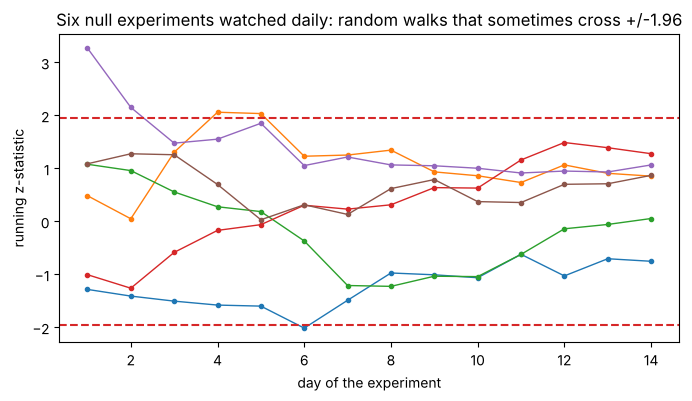

In [21]:
rng = np.random.default_rng(2024)

# ---- 1. design: baseline 5%, minimum detectable relative lift 10%, alpha 0.05 two-sided, power 0.8
base, rel_mde = 0.05, 0.10
p_a, p_b_min = base, base * (1 + rel_mde)
delta_min = p_b_min - p_a
alpha, power = 0.05, 0.80
za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
n = int(np.ceil((za + zb)**2 * (p_a * (1 - p_a) + p_b_min * (1 - p_b_min)) / delta_min**2))
visitors_per_day = 5_000
print(f"design: detect {p_a:.3f} -> {p_b_min:.4f} (delta = {delta_min:.4f}) with power {power} at alpha {alpha}")
print(f"required n per arm = {n:,}  ->  {2 * n:,} visitors in total = {2 * n / visitors_per_day:.1f} days at {visitors_per_day:,}/day")

# ---- 2. run the experiment once (the truth: a 10% relative lift) and analyse it
true_p_b = p_a * 1.10
x_a, x_b = rng.binomial(n, p_a), rng.binomial(n, true_p_b)
p1, p2 = x_a / n, x_b / n
pbar = (x_a + x_b) / (2 * n)
z = (p2 - p1) / np.sqrt(pbar * (1 - pbar) * 2 / n)
p_val = 2 * stats.norm.sf(abs(z))
se_ci = np.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
lo, hi = (p2 - p1) - 1.96 * se_ci, (p2 - p1) + 1.96 * se_ci
print(f"\nresult: A {x_a}/{n} = {p1:.4f}, B {x_b}/{n} = {p2:.4f}")
print(f"z = {z:.2f}, p = {p_val:.4f}; absolute lift {p2 - p1:+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]; relative lift {(p2 / p1 - 1) * 100:+.1f}%"
      f" (CI roughly [{lo / p1 * 100:+.1f}%, {hi / p1 * 100:+.1f}%])")
print("decision:", "ship" if p_val < alpha and lo > 0 else "do not ship")

# ---- 3. check the design by simulation: power at the MDE and false-positive rate under H0
reps = 4_000
xa = rng.binomial(n, p_a, reps); xb = rng.binomial(n, p_b_min, reps)
pb_ = (xa + xb) / (2 * n); zz = (xb / n - xa / n) / np.sqrt(pb_ * (1 - pb_) * 2 / n)
xa0 = rng.binomial(n, p_a, reps); xb0 = rng.binomial(n, p_a, reps)
pb0 = (xa0 + xb0) / (2 * n); zz0 = (xb0 / n - xa0 / n) / np.sqrt(pb0 * (1 - pb0) * 2 / n)
print(f"\nsimulated power at the MDE: {(np.abs(zz) > 1.96).mean():.3f}   false-positive rate under H0: {(np.abs(zz0) > 1.96).mean():.3f}")

# ---- 4. what daily peeking would have done: 14 looks, stop at the first p < 0.05
days = 14
per_day = n // days
def peek(p_b_true, sims=3_000):
    ca = rng.binomial(per_day, p_a, (sims, days)).cumsum(axis=1)
    cb = rng.binomial(per_day, p_b_true, (sims, days)).cumsum(axis=1)
    n_cum = np.arange(1, days + 1) * per_day
    pa_, pb_ = ca / n_cum, cb / n_cum
    pooled = (ca + cb) / (2 * n_cum)
    zd = (pb_ - pa_) / np.sqrt(pooled * (1 - pooled) * 2 / n_cum)
    sig = np.abs(zd) > 1.96
    stopped = sig.any(axis=1)
    first = np.argmax(sig, axis=1)
    lift_at_stop = (pb_ - pa_)[np.arange(sims), first]
    return stopped, first, lift_at_stop, zd

stopped0, first0, lift0, zd0 = peek(p_a)
print(f"\npeeking daily under H0 (no real effect): declared 'significant' at some point in {stopped0.mean():.3f} of experiments (nominal 0.05)")
print(f"   median stopping day among those: {np.median(first0[stopped0]) + 1:.0f}; mean |estimated lift| at stopping: {np.abs(lift0[stopped0]).mean():.4f} (truth 0)")
stopped1, first1, lift1, _ = peek(true_p_b)
early = stopped1 & (first1 < days - 1)
print(f"peeking daily under the true 10% lift: stopped before day 14 in {early.mean():.3f} of experiments;"
      f" mean estimated lift when stopping early {lift1[early].mean():+.4f} vs truth {true_p_b - p_a:+.4f} (winner's curse)")

fig, ax = plt.subplots(figsize=(8, 4))
for i in range(6):
    ax.plot(np.arange(1, days + 1), zd0[i], marker=".", lw=1)
ax.axhline(1.96, color="C3", ls="--"); ax.axhline(-1.96, color="C3", ls="--")
ax.set_xlabel("day of the experiment"); ax.set_ylabel("running z-statistic")
ax.set_title("Six null experiments watched daily: random walks that sometimes cross +/-1.96")
plt.show()

## Score

In [22]:
summary()


Score: 62/62 checks passed  🎉
